In [422]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sentinelhub import SHConfig
import getpass
import utils
import cdsapi
import xarray as xr
import requests
from scipy import stats

import importlib
importlib.reload(utils)

<module 'utils' from 'c:\\Users\\DavidCirauqui\\Desktop\\guardar\\personal\\drought_forecast_NDMI\\utils.py'>

In [ ]:
# config = SHConfig()
# config.sh_client_id = getpass.getpass("Enter your SentinelHub client id")
# config.sh_client_secret = getpass.getpass("Enter your SentinelHub client secret")
# config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
# config.sh_base_url = "https://sh.dataspace.copernicus.eu"
# config.save("cdse")


In [2]:
from sentinelhub import SHConfig
config = SHConfig("cdse")

In [ ]:
# coordinates for Empordà with irrigated crops (rice), dry farmlands (cereals), forest and scrub
coords = [2.97, 41.92, 3.19, 42.10]
resolution = 20
dates = [['2023', '07']]
# dates = ("2023-07-01", "2023-07-31")

ds = utils.get_index(coords, resolution, dates, config, index = "ndmi")


In [4]:
def get_mat(ds, date, variable):
    n_lat = ds.sizes['lat']
    n_lon = ds.sizes['lon']
    mat = ds.sel(time = date)[variable].to_numpy()
    mat = mat.reshape((n_lat, n_lon))
    return mat

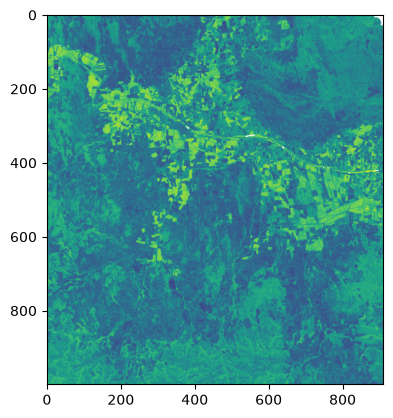

In [5]:
ndmi_mat = get_mat(ds, '2023-07-01', 'ndmi_median')
plt.imshow(ndmi_mat)

In [ ]:
# study area, period and variables
coords = [2.97, 41.92, 3.19, 42.10]   # Baix Empordà
resolution = 20
months = [[d.year, d.month] for d in pd.date_range("2017-04", "2025-12", freq="MS")]

era5_variables = [
    "total_precipitation",
    "2m_temperature",
    "potential_evaporation",
    "total_evaporation",
    "volumetric_soil_water_layer_1",
    "volumetric_soil_water_layer_2",
]

In [ ]:
# 1. get raw data, each at its native resolution

ndmi = utils.get_index(coords, resolution, dates, config, index = "ndmi")   # 20 m, defines the grid
ndvi = utils.get_index(coords, resolution, months, config, index = "ndvi") 
era5 = utils.get_era5(coords, months, era5_variables)            # ~9 km
dem = utils.get_dem(coords)                                      # 30 m
wc = utils.get_worldcover(coords)                                # 10 m

In [491]:
# 2. bring each source onto the NDMI grid, with its features, and merge
cube = xr.merge([
    ndmi,
    ndvi,
    utils.era5_to_grid(era5, ndmi),
    utils.dem_to_grid(dem, ndmi),
    utils.worldcover_to_grid(wc, ndmi),
])
cube

C:\Users\DavidCirauqui\AppData\Local\Temp\ipykernel_34976\99239324.py:2: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  cube = xr.merge([


<xarray.Dataset> Size: 3GB
Dimensions:                (time: 105, lat: 1000, lon: 910)
Coordinates:
  * time                   (time) datetime64[us] 840B 2017-04-01 ... 2025-12-01
  * lat                    (lat) float64 8kB 42.1 42.1 42.1 ... 41.92 41.92
  * lon                    (lon) float64 7kB 2.97 2.97 2.971 ... 3.189 3.19 3.19
Data variables: (12/26)
    ndmi_median            (time, lat, lon) float32 382MB 0.1721 ... -0.03355
    clear_count            (time, lat, lon) float32 382MB 6.0 6.0 ... 3.0 3.0
    ndvi_median            (time, lat, lon) float32 382MB 0.7481 ... 0.3222
    tp                     (time, lat, lon) float32 382MB 0.001044 ... 0.007493
    t2m                    (time, lat, lon) float32 382MB 287.3 287.3 ... 284.8
    pev                    (time, lat, lon) float32 382MB -0.006147 ... -0.00...
    ...                     ...
    lc_bare_sparse         (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_snow_ice            (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_water               (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_herbaceous_wetland  (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_mangroves           (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0
    lc_moss_lichen         (lat, lon) uint8 910kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0

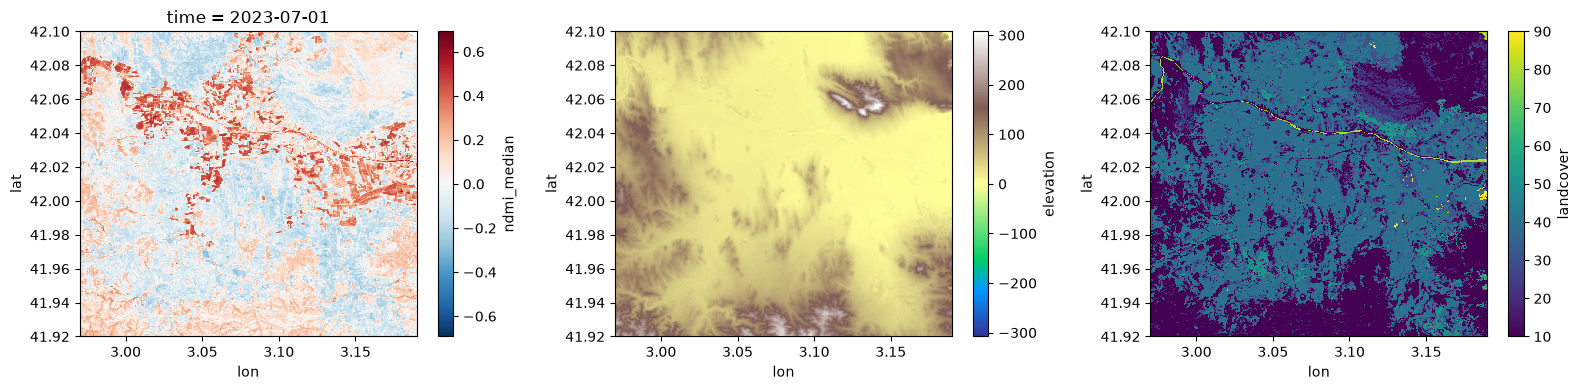

In [33]:
# quick check of the cube
fig, axes = plt.subplots(1, 3, figsize = (16, 4))
cube.ndmi_median.sel(time = "2023-07-01").plot(ax = axes[0])
cube.elevation.plot(ax = axes[1], cmap = "terrain")
cube.landcover.plot(ax = axes[2])
plt.tight_layout()

Compute anomalies with real observations

we only have 5 years in the training set: this will be enough for the mean, but stdv will be unstable if computed with that few points. Assume all months will have same spread (we loose some realism but gain better statistics): to this end, deseasonalise and then compute stdv

In [496]:
def compute_anomaly(da, train_years, min_obs = 30):
    # compute means among training split
    train = da.sel(time = train_years)

    # mean per pixel (mean is stable with few observations)
    mean = train.groupby("time.month").mean("time")

    # deseasonalise
    deviations = train.groupby("time.month") - mean

    # compute std over deseasonalised data
    std = deviations.std("time")

    return ((da.groupby("time.month") - mean) / std).where(train.count("time") >= min_obs)


cube["ndmi_anomaly"] = compute_anomaly(cube.ndmi_median, train_years = slice("2017", "2021"))
cube["ndvi_anomaly"] = compute_anomaly(cube.ndvi_median, train_years = slice("2017", "2021"))




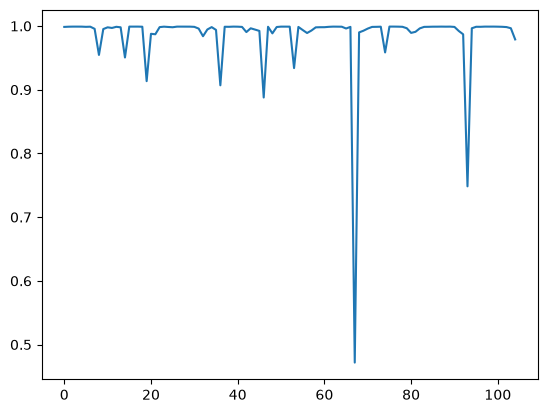

In [497]:
# let's check non-valid NDMI anomaly values
cube["valid_mask"] = cube.ndmi_anomaly.notnull().astype("uint8")


valid_ratio = cube.valid_mask.mean(["lat", "lon"])
plt.plot(valid_ratio)

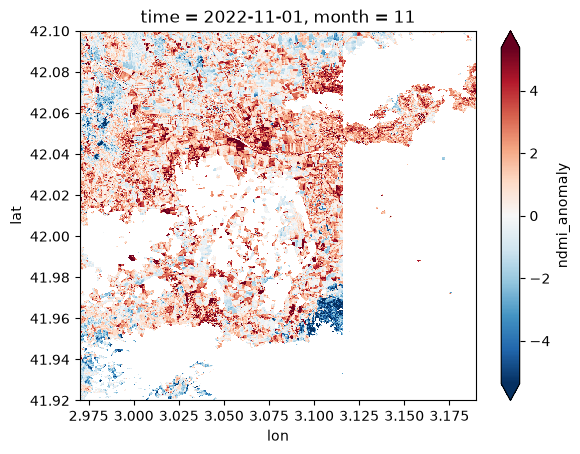

In [210]:
# we are missing data
idx = np.argmin(valid_ratio.values)
cube.ndmi_anomaly.sel(time = cube.time[idx]).plot(robust = True)

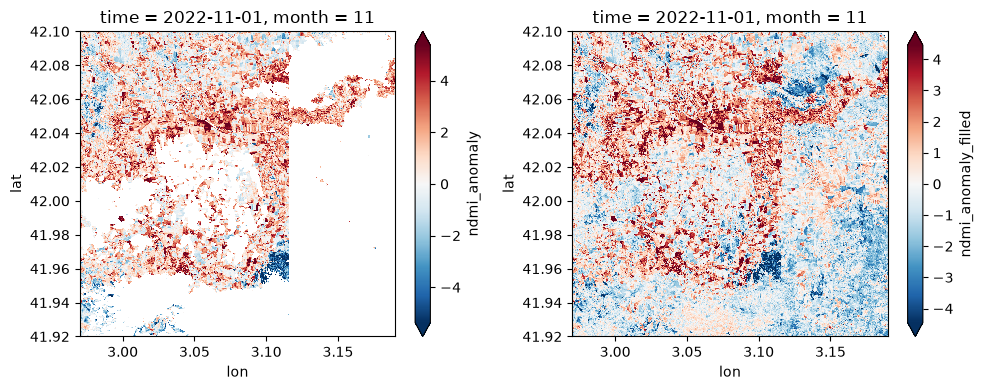

In [493]:
# interpolate missing values by persistence
cube["ndmi_anomaly_filled"] = cube.ndmi_anomaly.ffill("time", limit = 1)
cube["ndvi_anomaly_filled"] = cube.ndvi_anomaly.ffill("time", limit = 1)

fig, axes = plt.subplots(1, 2, figsize = (10, 4))
cube.ndmi_anomaly.sel(time = cube.time[idx]).plot(ax = axes[0], robust = True)
cube.ndmi_anomaly_filled.sel(time = cube.time[idx]).plot(ax = axes[1], robust = True)
plt.tight_layout()

directly filling with past info is clearly misleading when the season changes as we see there, some points are dryer than normal while some others are wetter we'll thus pass valid_mask to the model, so that it can learn which pixels to trust anyway, only a small proportion of the pixels need filling, so that's probably OK

important to note this in the README, since it can yield bad results
if bad results are obtained, explore better options for this (maybe a NN that learns how to fill the missing data?)

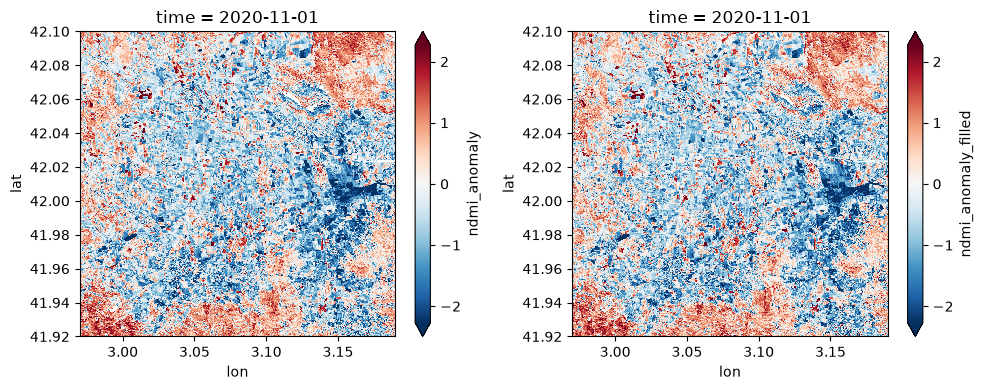

In [235]:
fig, axes = plt.subplots(1, 2, figsize = (10, 4))
cube.ndmi_anomaly.sel(time = cube.time[idx - 24]).plot(ax = axes[0], robust = True)
cube.ndmi_anomaly_filled.sel(time = cube.time[idx - 24]).plot(ax = axes[1], robust = True)
plt.tight_layout()

In [196]:
# encode month in sin and cos, to make the calendar circular (january 1 
# must be next to december 12), thus to avoid a model to learn a sharp jump
cube["month_sin"] = np.sin(cube.time.dt.month * 2 * np.pi / 12)
cube["month_cos"] = np.cos(cube.time.dt.month * 2 * np.pi / 12)

In [494]:
# save as zarr
cube.chunk({"time": -1, "lat": 128, "lon": 128}).to_zarr(
    "data/processed/cube.zarr", mode = "w")

c:\Users\DavidCirauqui\anaconda3\Lib\site-packages\zarr\api\asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


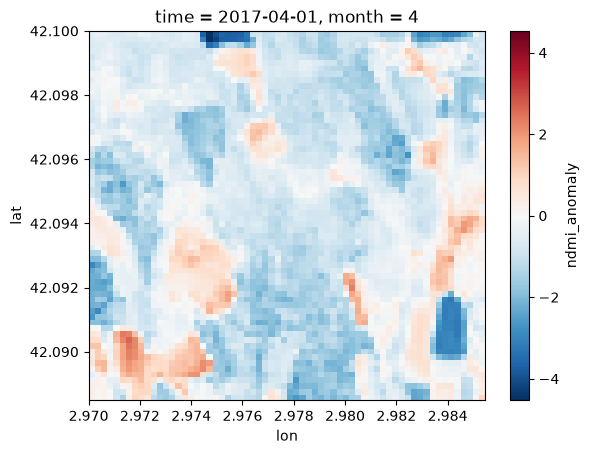

In [201]:
# read data
tile = cube.isel(lat = slice(0, 64), lon = slice(0, 64), time = 0).load()
# july = cube.ndmi_anomaly.sel(time = "2023-07-01").load()
tile.ndmi_anomaly.plot()


## Exploratory analysis

NDMI anomaly maps for summer 2021 against summer 2023

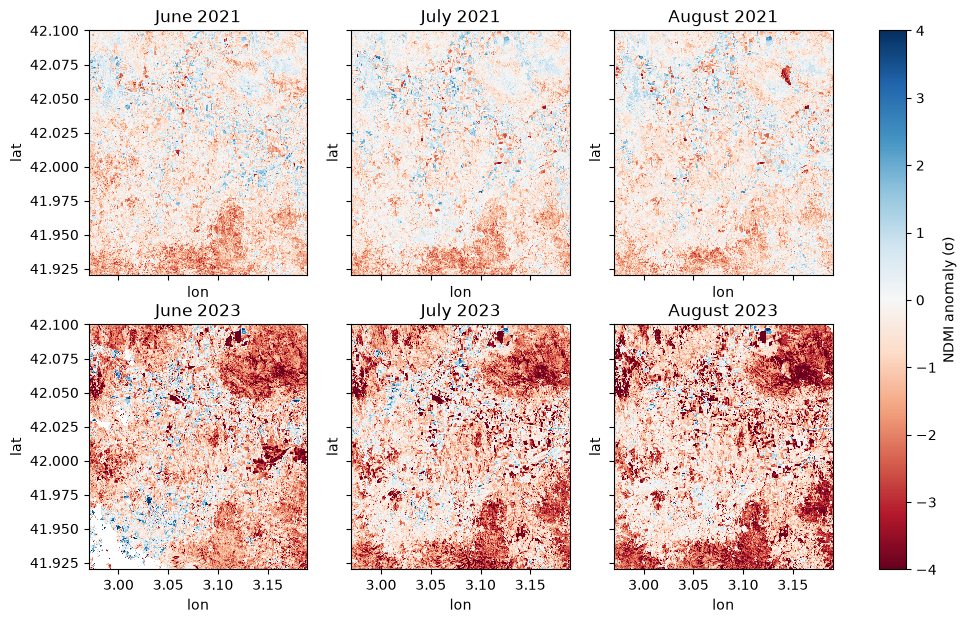

In [ ]:

fig, axes = plt.subplots(2, 3, figsize = (12, 7), sharex = True, sharey = True)
months = ['June', 'July', 'August']

for i, year in enumerate([2021, 2023]):
    for j, month in enumerate([6, 7, 8]):
        im = cube.ndmi_anomaly.sel(time = (cube.time.dt.year == year) & (cube.time.dt.month == month)).plot(ax = axes[i, j], 
            add_colorbar = False, vmin = -4, vmax = 4, cmap = "RdBu")
        axes[i, j].set_title(months[j] + ' ' + str(year))
# plt.tight_layout()

fig.colorbar(im, ax = axes, label = "NDMI anomaly (σ)")

Compute precipitation anomaly through the Standardised Precipitation Index (SPI)

In [375]:
months_all = [[d.year, d.month] for d in pd.date_range("1991-01", "2025-12", freq="MS")]

# mean daily precipitation
tp = utils.get_era5(coords, months_all, variables = ["total_precipitation"]) 

# monthly total accumulated in mm
tp_mm = utils.fill_sea(tp.tp) * 1000 * tp.time.dt.days_in_month

In [371]:
def spi(tp_mm, k, ref = slice("1991", "2020")):
    """SPI-k per grid cell: k-month precipitation total, compared with the same calendar month
    in the reference period through a gamma distribution, expressed as a standard normal value"""
    acc = tp_mm.rolling(time = k).sum()
    out = xr.full_like(acc, np.nan)
    for m in range(1, 13):
        in_m = (acc.time.dt.month == m).values
        ref_m = acc.sel(time = ref)
        ref_m = ref_m.isel(time = (ref_m.time.dt.month == m).values)
        for i in range(acc.sizes["lat"]):
            for j in range(acc.sizes["lon"]):
                shape, loc, scale = stats.gamma.fit(ref_m[:, i, j].dropna("time"), floc = 0)
                p = stats.gamma.cdf(acc[in_m, i, j], shape, loc, scale)
                out[in_m, i, j] = stats.norm.ppf(np.clip(p, 1e-6, 1 - 1e-6))
    return out

In [376]:
# SPI on the native grid, then regrid only the study period into the cube
for k in [3, 6, 12]:
    cube["spi" + str(k)] = utils.regrid(spi(tp_mm, k).sel(time = slice("2017-04", "2025-12")), ndmi, "bilinear")

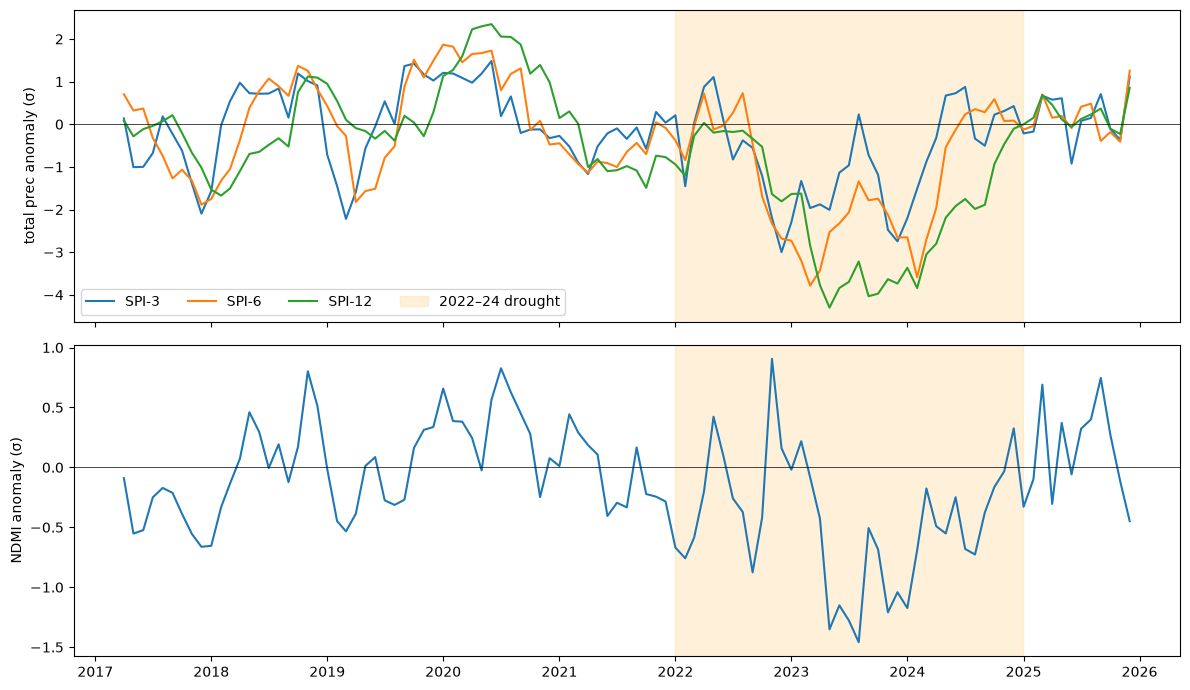

In [379]:
fig, axes = plt.subplots(2, 1, figsize = (12, 7), sharex = True)
cube.spi3.mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = 'SPI-3')
cube.spi6.mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = 'SPI-6')
cube.spi12.mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = 'SPI-12')
cube.ndmi_anomaly.mean(dim = ["lat", "lon"]).plot(ax = axes[1], label = 'ndmi anomaly')

for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), color = "orange", alpha = 0.15, label = "2022–24 drought")
    ax.set_xlabel("")


axes[0].set_ylabel("total prec anomaly (σ)")
axes[1].set_ylabel("NDMI anomaly (σ)")
axes[0].axhline(0, color = "k", lw = 0.5)
axes[1].axhline(0, color = "k", lw = 0.5)
axes[0].legend(ncol = 5)
plt.tight_layout()

Correlation between NDMI and rain anomaly at N months lag

In [418]:
# time series of means over the whole area
df = pd.DataFrame()
df['ndmi_ts'] = cube.ndmi_anomaly.mean(["lat", "lon"])
for col in ['spi3', 'spi6', 'spi12']:
    df[col] = cube[col].mean(["lat", "lon"])

df.head()

,ndmi_ts,spi3,spi6,spi12
0,-0.090120,0.136874,0.702335,0.085202
1,-0.552160,-1.006776,0.321261,-0.282963
2,-0.523716,-0.998345,0.369117,-0.113490
3,-0.250093,-0.674639,-0.321459,-0.037788
4,-0.171656,0.183432,-0.738276,0.072757


Text(0.5, 0, 'lag months')

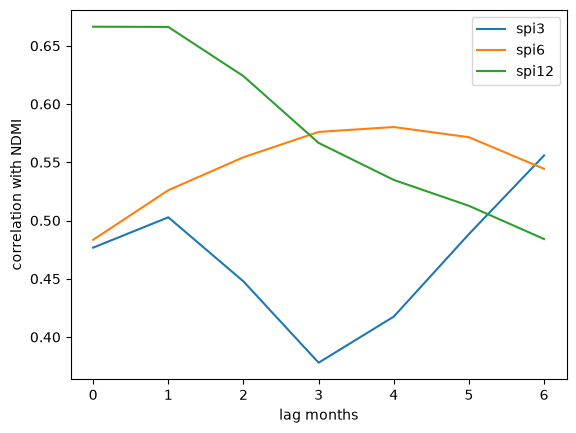

In [420]:
df.ndmi_ts.corr(df.spi3.shift(1))
lags = range(0, 7)
corr = pd.DataFrame(columns = ['spi3', 'spi6', 'spi12'])
for col in corr.columns:
    corr[col] = [df.ndmi_ts.corr(df[col].shift(L)) for L in lags]

corr.plot()
plt.legend()
plt.ylabel('correlation with NDMI')
plt.xlabel('lag months')

on the train data, look for irrigated cropfields (kept wet artificially, as compared to rain-fed crops)

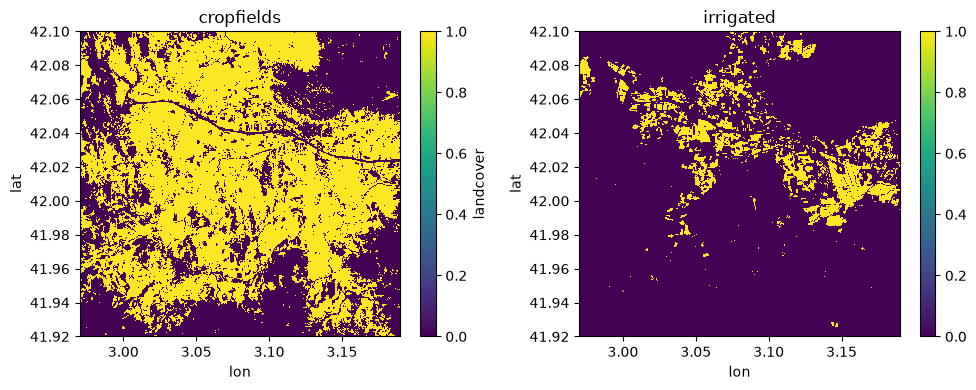

In [495]:
train_ndmi = cube.ndmi_median.sel(time = slice("2017", "2021"))
summer_ndmi = train_ndmi.where(train_ndmi.time.dt.month.isin([7, 8])).mean("time")
cropfields = cube.landcover.isin([30, 40]) # account for grassland and cropland

WET = .25
cube["irrigated"] = (cropfields & (summer_ndmi > WET)).astype("uint8")

fig, axes = plt.subplots(1, 2, figsize = (10, 4))
cropfields.plot(ax = axes[0])
(cropfields & (summer_ndmi > WET)).plot(ax = axes[1])

axes[0].title.set_text('cropfields')
axes[1].title.set_text('irrigated')
plt.tight_layout()

How did the ndmi median and its anomaly evolve during the whole period? Let's plot, for each type of land cover, the evolution of their means over the whole area

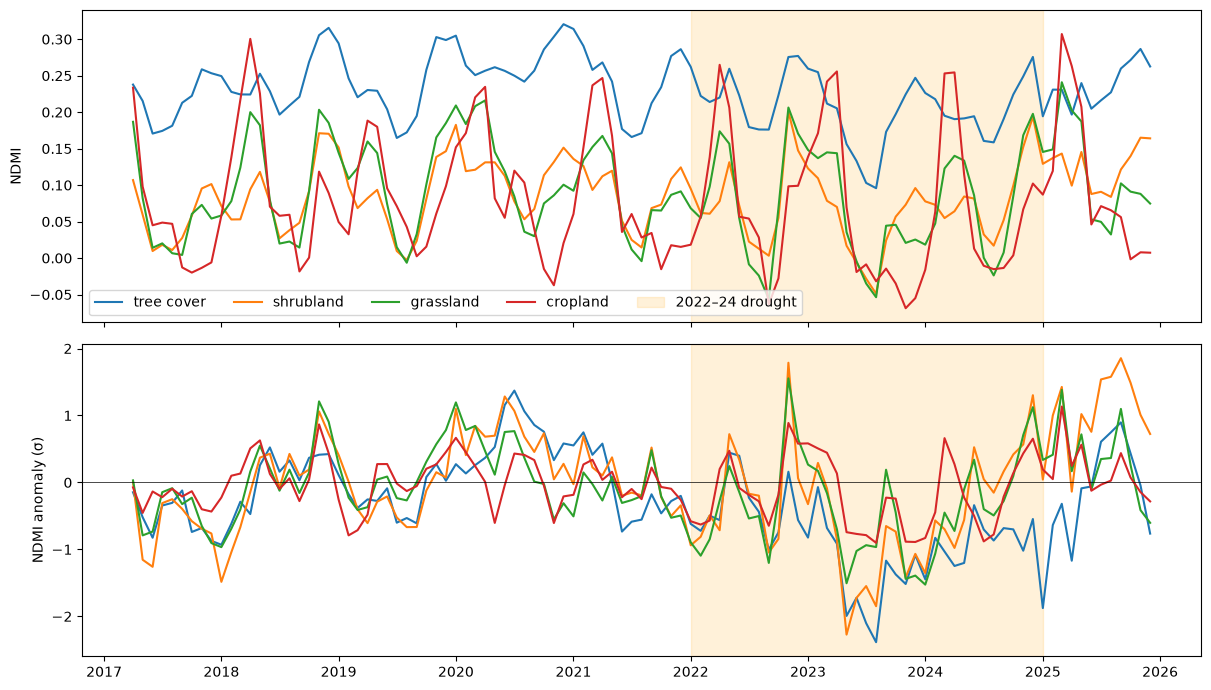

In [487]:
world_classess = {10: "tree cover", 20: "shrubland", 30: "grassland", 40: "cropland"}
fig, axes = plt.subplots(2, 1, figsize = (12, 7), sharex = True)

for cover_type in world_classess.keys():
    lc_condition = cube["landcover"] == cover_type
    cube.ndmi_median.where(lc_condition).mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = world_classess[cover_type])
    cube.ndmi_anomaly.where(lc_condition).mean(dim = ["lat", "lon"]).plot(ax = axes[1], label = world_classess[cover_type])


for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), color = "orange", alpha = 0.15, label = "2022–24 drought")
    ax.set_xlabel("")


axes[0].set_ylabel("NDMI")
axes[1].set_ylabel("NDMI anomaly (σ)")
axes[1].axhline(0, color = "k", lw = 0.5)
axes[0].legend(ncol = 5)
plt.tight_layout()

let us compare these same metrics for irrigated and non-irrigated croplands only

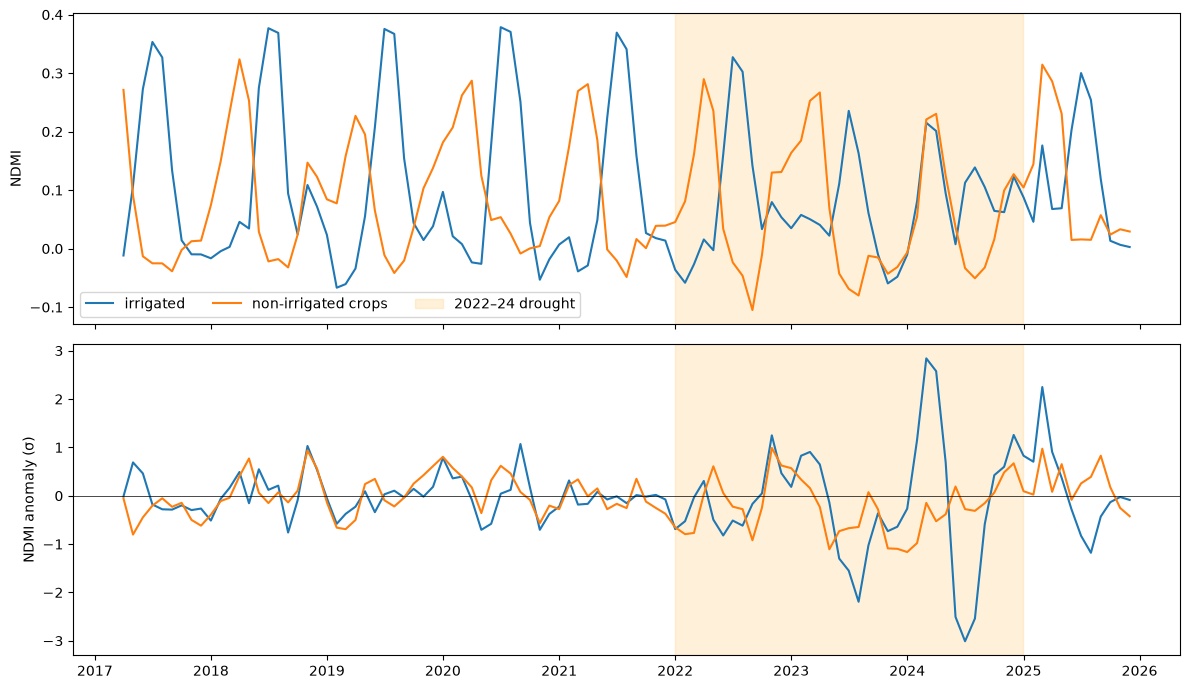

In [ ]:
fig, axes = plt.subplots(2, 1, figsize = (12, 7), sharex = True)

masks = {"irrigated" : (cube.irrigated == 1),
         "non-irrigated crops": (cube.irrigated == 0) & cube.landcover.isin([30, 40])}

for name, mask in masks.items():
    cube.ndmi_median.where(mask).mean(["lat", "lon"]).plot(ax = axes[0], label = name)
    cube.ndmi_anomaly.where(mask).mean(["lat", "lon"]).plot(ax = axes[1], label = name)


for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), color = "orange", alpha = 0.15, label = "2022–24 drought")
    ax.set_xlabel("")

axes[0].set_ylabel("NDMI")
axes[1].set_ylabel("NDMI anomaly (σ)")
axes[1].axhline(0, color = "k", lw = 0.5)
axes[0].legend(ncol = 5)
plt.tight_layout()

irrigated fields do not stay wet during the drought: maybe an irrigation restriction

compare NDMI and NDVI

In [512]:
masks = {"irrigated" : (cube.irrigated == 1),
         "non-irrigated crops": (cube.irrigated == 0) & cube.landcover.isin([30, 40]),
         "forest": cube.landcover == 10}
lags = range(-3, 4)

corr = pd.DataFrame()
corr["lag months"] = lags
for key, mask in masks.items():
    # time series for ndvi and ndmi anomalies
    ndvi_ts = cube.ndvi_anomaly.where(mask).mean(dim = ["lat", "lon"])
    ndmi_ts = cube.ndmi_anomaly.where(mask).mean(dim = ["lat", "lon"])

    # correlation at different month lags
    r = [float(xr.corr(ndvi_ts, ndmi_ts.shift(time = L))) for L in lags]
    corr[key] = np.round(r, 2)
    
corr

,lag months,irrigated,non-irrigated crops,forest
0,-3,-0.25,0.02,0.28
1,-2,0.11,0.21,0.34
2,-1,0.60,0.58,0.49
3,0,0.94,0.91,0.67
4,1,0.75,0.55,0.48
5,2,0.29,0.22,0.48
6,3,-0.21,0.01,0.29


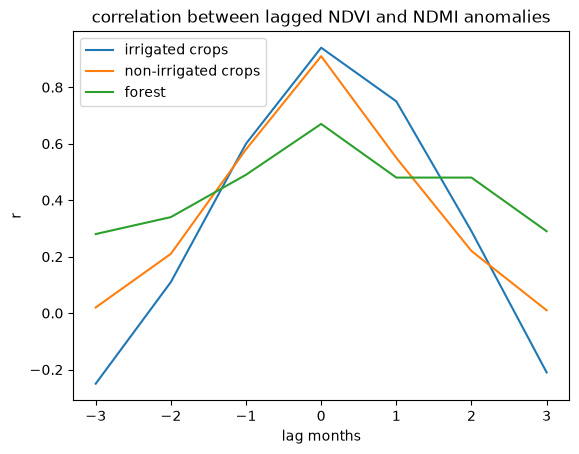

In [524]:
plt.plot(corr["lag months"], corr["irrigated"], label = 'irrigated crops')
plt.plot(corr["lag months"], corr["non-irrigated crops"], label = 'non-irrigated crops')
plt.plot(corr["lag months"], corr["forest"], label = 'forest')
plt.xlabel("lag months")
plt.ylabel("r")
plt.title("correlation between lagged NDVI and NDMI anomalies")
plt.legend()

the curve is centered at zero but assymetric, with higher values at positive lags, so NDMI comes first